## SMHR-19 — Classification Model Development

### DummyClassifier Baseline

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('../data/raw/student_mental_health.csv')

X = df.drop(columns=['Student_ID', 'Mental_Health_Risk'])
y = df['Mental_Health_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print('Training shape', X_train.shape)
print('test_shape', X_test.shape)

Training shape (1600, 15)
test_shape (400, 15)


In [5]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy='most_frequent')

dummy_model.fit(X_train, y_train)

train_accuracy = dummy_model.score(X_train, y_train)

print("DummyClassifier training accuracy:", train_accuracy)

DummyClassifier training accuracy: 0.34


### Reusable Preprocessing Pipeline

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(include=["str", "category", "object"]).columns


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

print("Numerical features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))

Numerical features: 10
Categorical features: 5


### Logistic Regression Model

In [17]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


### Logistic Regression Training Accuracy

In [18]:
logistic_accuracy = logistic_model.score(X_train, y_train)

print("DummyClassifier accuracy:", train_accuracy)
print("Logistic Regression accuracy:", logistic_accuracy)

DummyClassifier accuracy: 0.34
Logistic Regression accuracy: 0.76625


### Logistic Regression Cross-Validation

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Validation accuracies:", cv_scores)
print("Mean validation accuracy:", cv_scores.mean())

Validation accuracies: [0.73970037 0.75422139 0.76172608]
Mean validation accuracy: 0.751882613899605


### Logistic Regression Classification Report

In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

cv_predictions = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv
)

print(classification_report(y_train, cv_predictions))

              precision    recall  f1-score   support

        High       0.81      0.81      0.81       544
         Low       0.81      0.81      0.81       528
      Medium       0.63      0.63      0.63       528

    accuracy                           0.75      1600
   macro avg       0.75      0.75      0.75      1600
weighted avg       0.75      0.75      0.75      1600



### Logistic Regression Confusion Matrix

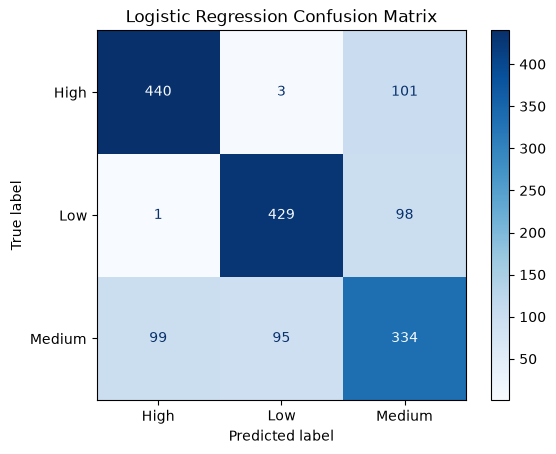

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_train,
    cv_predictions,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

### DummyClassifier Cross-Validation

In [27]:
dummy_cv_scores = cross_val_score(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Dummy validation scores:", dummy_cv_scores)
print("Dummy mean validation accuracy:", dummy_cv_scores.mean())

Dummy validation scores: [0.34082397 0.33958724 0.33958724]
Dummy mean validation accuracy: 0.339999484696662


### SMHR-19 — Logistic Regression Baseline Results

**Models**
- DummyClassifier (most_frequent)
- Logistic Regression with preprocessing Pipeline

**Evaluation**
- Training set: 1,600 records
- Cross-validation: Stratified 3-fold
- Independent test set: Not used

**Results**
- DummyClassifier training accuracy: 34.00%
- DummyClassifier mean CV accuracy: 34.00%
- Logistic Regression training accuracy: 76.63%
- Logistic Regression mean CV accuracy: 75.19%

**Classification Report**
- High F1-score: 0.81
- Low F1-score: 0.81
- Medium F1-score: 0.63

**Observations**
- Logistic Regression substantially outperforms the dummy baseline.
- Training and validation accuracy are similar.
- There is no clear evidence of severe overfitting.
- The Medium category is harder to classify.
- Further model comparisons are needed to investigate underfitting.

**Limitations**
- Results are based on cross-validation, not independent test evaluation.
- The dataset's label-generation process is not independently verified.
- Predictions are for educational purposes, not clinical diagnosis.

### Support Vector Classifier (SVC)

In [28]:
from sklearn.svm import SVC

svc_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(kernel="rbf"))
])

svc_model.fit(X_train, y_train)

print("SVC trained successfully!")

SVC trained successfully!


### SVC Training Accuracy

In [29]:
svc_train_accuracy = svc_model.score(X_train, y_train)

print("SVC Training Accuracy:", svc_train_accuracy)

SVC Training Accuracy: 0.82875


### SVC Cross-Validation

In [31]:
svc_cv_scores = cross_val_score(
    svc_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("SVC validation accuracies:", svc_cv_scores)
print("SVC mean validation accuracy:", svc_cv_scores.mean())

SVC validation accuracies: [0.70411985 0.71106942 0.73733583]
SVC mean validation accuracy: 0.7175083678235227


### SVC Classification Report

In [32]:
svc_cv_predictions = cross_val_predict(
    svc_model,
    X_train,
    y_train,
    cv=cv
)

print(classification_report(y_train, svc_cv_predictions))

              precision    recall  f1-score   support

        High       0.79      0.75      0.77       544
         Low       0.80      0.80      0.80       528
      Medium       0.58      0.61      0.59       528

    accuracy                           0.72      1600
   macro avg       0.72      0.72      0.72      1600
weighted avg       0.72      0.72      0.72      1600



### SVC Confusion Matrix

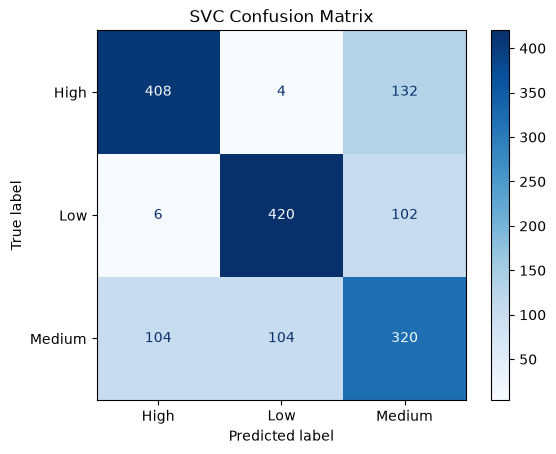

In [35]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    svc_cv_predictions,
    cmap="Blues"
)

plt.title("SVC Confusion Matrix")
plt.show()

### SVC Cross-Validation Stability

In [36]:
print("SVC Mean Accuracy:", svc_cv_scores.mean())
print("SVC Standard Deviation:", svc_cv_scores.std())

print("Logistic Regression Standard Deviation:", cv_scores.std())

SVC Mean Accuracy: 0.7175083678235227
SVC Standard Deviation: 0.014304322480650328
Logistic Regression Standard Deviation: 0.009142768057448954


### SMHR-20 — SVC Baseline Results

**Model:** Support Vector Classifier (RBF Kernel)

**Training and Evaluation**
- Training records: 1,600
- Cross-validation: Stratified 3-fold
- Preprocessing: Imputation, Scaling, OneHotEncoding
- Independent test set: Not used

**Performance**
- Training Accuracy: 82.88%
- Mean CV Accuracy: 71.75%
- CV Standard Deviation: 1.43 percentage points
- Macro F1-score: 0.72

**Per-Class F1-Scores**
- High: 0.77
- Low: 0.80
- Medium: 0.59

**Observations**
- SVC achieved higher training accuracy than Logistic Regression.
- Logistic Regression achieved better validation accuracy.
- SVC showed a larger training–validation gap,
  suggesting possible overfitting.
- Medium was the most difficult class to classify.
- Default RBF SVC may benefit from hyperparameter tuning.

**Conclusion**
Logistic Regression is currently the stronger baseline.
SVC remains a candidate for optimization in Epic 5.

**Limitations**
- Only three validation folds were used.
- The independent test set remains untouched.
- Predictions are educational, not clinical diagnoses.

### Random Forest Classifier

In [38]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


### Random Forest Training Accuracy

In [41]:
rf_train_accuracy = rf_model.score(X_train, y_train)

print("Random Forest Training Accuracy:", rf_train_accuracy)

Random Forest Training Accuracy: 1.0


### Random Forest Cross-Validation

In [44]:
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Random Forest Validation Accuracies:", rf_cv_scores)
print("Random Forest Mean Validation Accuracy:", rf_cv_scores.mean())

Random Forest Validation Accuracies: [0.69662921 0.66228893 0.65478424]
Random Forest Mean Validation Accuracy: 0.6712341280716179


### Random Forest Classification Report

In [45]:
rf_cv_predictions = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=cv
)

print(classification_report(y_train, rf_cv_predictions))

              precision    recall  f1-score   support

        High       0.72      0.80      0.76       544
         Low       0.72      0.78      0.75       528
      Medium       0.54      0.43      0.48       528

    accuracy                           0.67      1600
   macro avg       0.66      0.67      0.66      1600
weighted avg       0.66      0.67      0.66      1600



### Random Forest Confusion Matrix

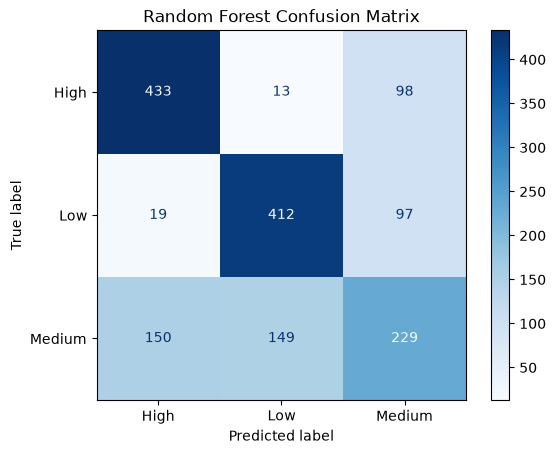

In [46]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_cv_predictions,
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

### Random Forest Cross-Validation Stability

In [47]:
print("Random Forest Mean Accuracy:", rf_cv_scores.mean())
print("Random Forest Standard Deviation:", rf_cv_scores.std())
print("Random Forest Training Accuracy:", rf_train_accuracy)

Random Forest Mean Accuracy: 0.6712341280716179
Random Forest Standard Deviation: 0.018216528518762806
Random Forest Training Accuracy: 1.0


### SMHR-21 — Random Forest Baseline Results

**Model:** RandomForestClassifier (100 trees)

**Training and Evaluation**
- Training records: 1,600
- Cross-validation: Stratified 3-fold
- Preprocessing: Existing Pipeline
- Independent test set: Not used

**Performance**
- Training Accuracy: 100%
- Mean CV Accuracy: 67.12%
- CV Standard Deviation: 1.82 percentage points
- Training–Validation Gap: 32.88 percentage points
- Macro F1-score: 0.66

**Per-Class F1-Scores**
- High: 0.76
- Low: 0.75
- Medium: 0.48

**Observations**
- Random Forest shows strong signs of overfitting.
- Medium is the hardest category to classify.
- Logistic Regression currently has better
  cross-validation performance.
- Limiting tree depth may improve generalization.

**Conclusion**
The default Random Forest is not our strongest baseline.
We will investigate hyperparameter tuning in Epic 5.

**Limitations**
- Only three validation folds were used.
- Feature importance has not yet been analyzed.
- The independent test set remains untouched.
- Results are not clinical diagnoses.

### SMHR-22 — Baseline Model Comparison

In [49]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "SVC", "Random Forest"],
    "Training (%)": [
        logistic_accuracy * 100,
        svc_train_accuracy * 100,
        rf_train_accuracy * 100
    ],
    "CV Mean (%)": [
        cv_scores.mean() * 100,
        svc_cv_scores.mean() * 100,
        rf_cv_scores.mean() * 100
    ],
    "CV Std (pp)": [
        cv_scores.std() * 100,
        svc_cv_scores.std() * 100,
        rf_cv_scores.std() * 100
    ]
})

comparison["Gap (pp)"] = comparison["Training (%)"] - comparison["CV Mean (%)"]

display(comparison.round(2))

,Model,Training (%),CV Mean (%),CV Std (pp),Gap (pp)
0,Logistic Regression,76.62,75.19,0.91,1.44
1,SVC,82.88,71.75,1.43,11.12
2,Random Forest,100.00,67.12,1.82,32.88


### Model Comparison — Macro F1-Score

In [50]:
from sklearn.metrics import f1_score

comparison["Macro F1"] = [
    f1_score(y_train, cv_predictions, average="macro"),
    f1_score(y_train, svc_cv_predictions, average="macro"),
    f1_score(y_train, rf_cv_predictions, average="macro")
]

display(comparison.round(2))

,Model,Training (%),CV Mean (%),CV Std (pp),Gap (pp),Macro F1
0,Logistic Regression,76.62,75.19,0.91,1.44,0.75
1,SVC,82.88,71.75,1.43,11.12,0.72
2,Random Forest,100.00,67.12,1.82,32.88,0.66


### Model Comparison Visualization

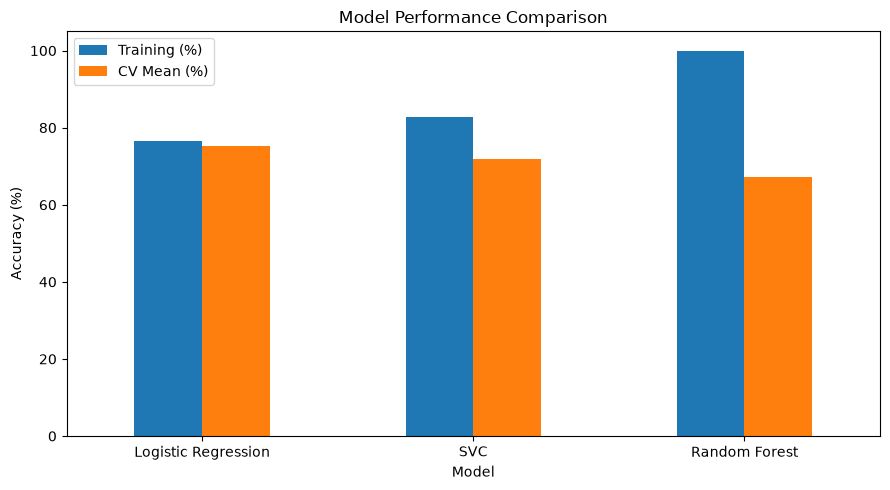

In [58]:
comparison.plot(
    x="Model",
    y=["Training (%)", "CV Mean (%)"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### SMHR-22 — Model Comparison Conclusions

**Models Evaluated**
- Logistic Regression
- Support Vector Classifier (RBF)
- Random Forest (100 trees)

**Evaluation Strategy**
- Stratified 3-Fold Cross-Validation
- Same training dataset and folds for all models
- Preprocessing fitted within each training fold
- Independent test dataset remains untouched

**Key Findings**

1. Logistic Regression achieved the highest mean
   validation accuracy (75.19%) and macro F1 (0.75).

2. Logistic Regression showed the smallest
   training-validation gap (1.44 percentage points).

3. SVC achieved 71.75% mean validation accuracy
   and showed possible overfitting.

4. Random Forest achieved 100% training accuracy
   but only 67.12% validation accuracy,
   indicating substantial overfitting.

5. Medium Risk was the hardest class to predict
   for all three models.

6. Logistic Regression had the lowest variation
   between validation folds.

**Models Selected for Optimization**
- Primary: Logistic Regression
- Secondary: Random Forest
- Optional: SVC

**Next Steps**
- Perform hyperparameter tuning in Epic 5.
- Use cross-validation to compare tuned models.
- Select the strongest model before evaluating
  the untouched test dataset.

**Limitations**
- Evaluation used only three validation folds.
- Results may change with different data.
- The labels are not independently clinically validated.
- These models must not be used for diagnosis.